# Perceptrón Simple (Rossenblatt)

<div align="center">
<img src='./img/perceptron.png' width="600px">
</div>

## Implementación de un perceptrón en Python

### Definición de la función de cálculo - suma ponderada   

Cálculo simple en el que le pasamos al **perceptrón** los valores tanto de la variable de entrada (x) como del peso correspondiente (w). Se le asigna también un valor de *bias* o *sesgo*, inicialmente a 0.

In [1]:

# El primer elemento del vector x debe ser 1, ya que representa el sesgo (bias) de la neurona.
# La longitud de w y x debe ser n+1 para una neurona con n entradas.
def compute_output(w, x):
    z = 0.0
    for i in range(len(w)):
        z += x[i] * w[i] # Calcula la suma de las entradas ponderadas
    if z < 0: # Aplica la función de activación escalón
        return -1
    else:
        return 1

Función de ploteado del aprendizaje del Perceptrón

In [ ]:
import matplotlib.pyplot as plt
import random

# Definimos las variables necesarias para la representación gráfica.
color_list = ['r-', 'm-', 'y-', 'c-', 'b-', 'g-']
color_index = 0

# Función para mostrar el estado de aprendizaje del perceptrón.
def show_learning_new(w):
    global color_index
    print('w0 =', '%5.2f' % w[0], ', w1 =', '%5.2f' % w[1],', w2 =', '%5.2f' % w[2]) # Imprime los pesos actuales
    if color_index == 0:
        plt.plot([1.0], [1.0], 'b_', markersize=12)
        plt.plot([-1.0, 1.0, -1.0], [1.0, -1.0, -1.0],'r+', markersize=12)
        plt.axis([-2.0, 2.0, -2.0, 2.0])
        plt.xlabel('x1')
        plt.ylabel('x2')
    x = [-2.0, 2.0]
    if abs(w[2]) < 1e-5: # Evita la división por cero si w[2] es muy pequeño
        y = [-w[1]/(1e-5)*(-2.0)+(-w[0]/(1e-5)),-w[1]/(1e-5)*(2.0)+(-w[0]/(1e-5))] # Calcula los valores de y para la línea de decisión
    else:
        y = [-w[1]/w[2]*(-2.0)+(-w[0]/w[2]),-w[1]/w[2]*(2.0)+(-w[0]/w[2])] # Calcula los valores de y para la línea de decisión
    plt.plot(x, y, color_list[color_index])
    if color_index < (len(color_list) - 1):
        color_index += 1

Preparación de los datos

In [3]:
# Definimos las variables necesarias para controlar el proceso de entrenamiento.
random.seed(7) # semilla para que los resultados sean reproducibles
LEARNING_RATE = 0.1
index_list = [0, 1, 2, 3] # para recorrer los ejemplos de entrenamiento en orden aleatorio


# Definimos los ejemplos de entrenamiento. Cada ejemplo es un vector de entrada x y un valor de salida y.
x_train = [(1.0, -1.0, -1.0), (1.0, -1.0, 1.0),
    (1.0, 1.0, -1.0), (1.0, 1.0, 1.0)] # Inputs
y_train = [1.0, 1.0, 1.0, -1.0] # Output 

Entrenamiento del Perceptrón

w0 =  0.20 , w1 = -0.60 , w2 =  0.25
w0 =  0.30 , w1 = -0.50 , w2 =  0.15
w0 =  0.40 , w1 = -0.40 , w2 =  0.05
w0 =  0.30 , w1 = -0.50 , w2 = -0.05
w0 =  0.40 , w1 = -0.40 , w2 = -0.15


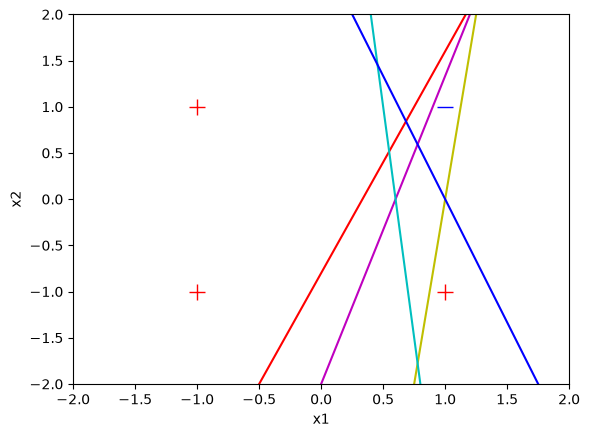

In [ ]:

# Definimos los pesos del perceptrón.

w = [0.2, -0.6, 0.25] # inicializamos a algunos números "aleatorios"
show_learning_new(w) # Mostrar pesos iniciales

# Bucle de entrenamiento del Perceptron.
all_correct = False
while not all_correct:
    all_correct = True
    random.shuffle(index_list) # Ordenamos aleatoriamente los ejemplos de entrenamiento
    for i in index_list:
        x = x_train[i] # Seleccionamos el ejemplo de entrenamiento i-ésimo
        y = y_train[i]
        p_out = compute_output(w, x) # Llamada a la función de salida del perceptrón
        
        if y != p_out: # Actualizamos los pesos si la salida es incorrecta
            for j in range(0, len(w)):
                w[j] += (y * LEARNING_RATE * x[j]) # Actualizamos el peso j-ésimo
            all_correct = False
            show_learning_new(w) # Mostrar pesos actualizados

### Interpretación del gráfico de salida.     

El gráfico resultante anterior muestra los cuatro puntos de entrada, que aparecen representados como tres signos más y un signo menos. La *línea roja corresponde al conjunto inicial de pesos*, que no divide correctamente el gráfico entre los signos más y menos.
Para cada actualización de los pesos, trazamos otra línea siguiendo este orden de colores: magenta, amarillo, cian y azul. La *línea azul divide correctamente* el gráfico, con todos los signos más a un lado y el signo menos al otro, por lo que el algoritmo de aprendizaje finaliza.
